<a href="https://colab.research.google.com/github/sreeramchennakrish/MIDS-281-project/blob/main/notebooks/05_classifier_logreg_rf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05. Other classifiers (logistic regression and random forest)

Parul. Alternatives to the SVM in `04_classifier_svm.ipynb`, using the same combined 8206-d features (and a PCA-95% variant).


In [1]:
# Colab setup
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip -q install numpy pandas matplotlib scikit-learn joblib
    if not os.path.exists("/content/MIDS-281-project/.git"):
        !git clone --depth 1 https://github.com/sreeramchennakrish/MIDS-281-project.git /content/MIDS-281-project
    %cd /content/MIDS-281-project/notebooks

print("cwd:", os.getcwd())


Cloning into '/content/MIDS-281-project'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 27 (delta 2), reused 22 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (27/27), 148.79 MiB | 16.73 MiB/s, done.
Resolving deltas: 100% (2/2), done.
Updating files: 100% (25/25), done.
/content/MIDS-281-project/notebooks
cwd: /content/MIDS-281-project/notebooks


## Load combined features


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

FEATURE_DIR = Path("../features").resolve()
OUTPUT_DIR = Path("../outputs/dimred").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with np.load(FEATURE_DIR / "combined_weighted_features.npz") as data:
    X_train = data["X_train"]
    X_val = data["X_val"]
    y_train = data["y_train"]
    y_val = data["y_val"]
    classes = np.asarray(data["classes"])
    feature_groups = data["feature_groups"]
    feature_dimensions = data["feature_dimensions"]
    feature_weights = data["feature_weights"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Classes:", classes)
for name, dim, weight in zip(feature_groups, feature_dimensions, feature_weights):
    print(f"{name}: {dim} features, weight={weight}")


Training features: (2160, 8206)
Validation features: (541, 8206)
Classes: ['Fire' 'Smoke' 'Neutral']
rgb: 48 features, weight=1.0
hsv: 48 features, weight=1.0
lbp: 10 features, weight=1.0
hog: 8100 features, weight=1.0


## Train and evaluate


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, precision_score, recall_score,
)

MODEL_DIR = Path("../models/other_classifiers").resolve()
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def evaluate(name, model, Xtr, ytr, Xva, yva):
    model.fit(Xtr, ytr)
    pred = model.predict(Xva)
    print("=" * 60)
    print(name)
    print("Accuracy:", accuracy_score(yva, pred))
    print(classification_report(yva, pred, target_names=classes))
    ConfusionMatrixDisplay.from_predictions(yva, pred, display_labels=classes, cmap="Blues")
    plt.title(name)
    plt.show()
    return {
        "Model": name,
        "Accuracy": accuracy_score(yva, pred),
        "Precision": precision_score(yva, pred, average="macro"),
        "Recall": recall_score(yva, pred, average="macro"),
        "F1 Score": f1_score(yva, pred, average="macro"),
        "pred": pred,
        "fitted": model,
    }


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic regression (combined 8206-d)
Accuracy: 0.8207024029574861
              precision    recall  f1-score   support

        Fire       0.84      0.81      0.83       180
       Smoke       0.78      0.80      0.79       180
     Neutral       0.84      0.85      0.84       181

    accuracy                           0.82       541
   macro avg       0.82      0.82      0.82       541
weighted avg       0.82      0.82      0.82       541



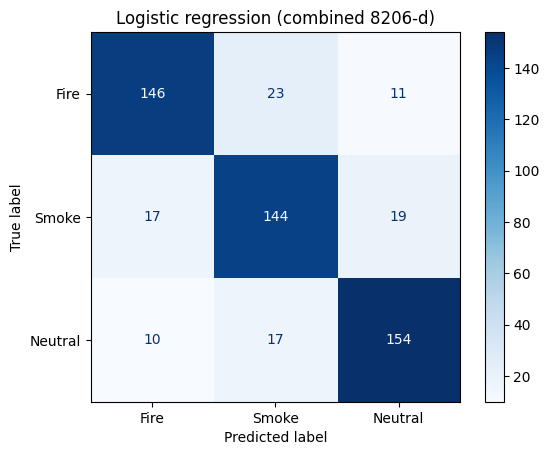

Random forest (combined 8206-d)
Accuracy: 0.7781885397412199
              precision    recall  f1-score   support

        Fire       0.79      0.75      0.77       180
       Smoke       0.73      0.80      0.76       180
     Neutral       0.82      0.78      0.80       181

    accuracy                           0.78       541
   macro avg       0.78      0.78      0.78       541
weighted avg       0.78      0.78      0.78       541



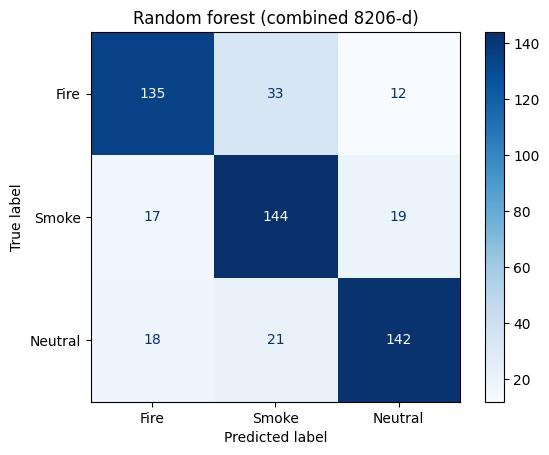

PCA 95% components: 666
Logistic regression (PCA 666-d)
Accuracy: 0.8151571164510166
              precision    recall  f1-score   support

        Fire       0.86      0.79      0.82       180
       Smoke       0.77      0.82      0.79       180
     Neutral       0.82      0.83      0.83       181

    accuracy                           0.82       541
   macro avg       0.82      0.82      0.82       541
weighted avg       0.82      0.82      0.82       541



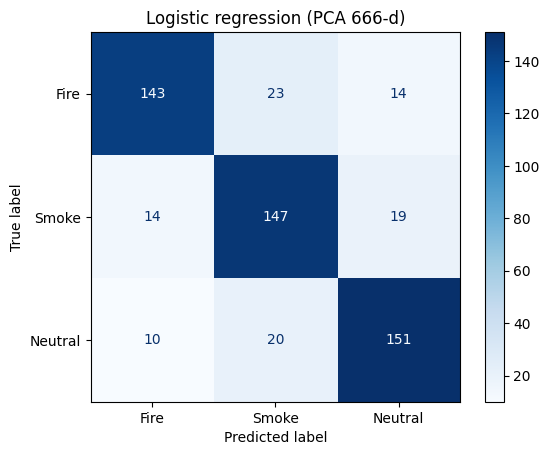

Random forest (PCA 666-d)
Accuracy: 0.7615526802218114
              precision    recall  f1-score   support

        Fire       0.83      0.69      0.75       180
       Smoke       0.72      0.78      0.75       180
     Neutral       0.75      0.81      0.78       181

    accuracy                           0.76       541
   macro avg       0.77      0.76      0.76       541
weighted avg       0.77      0.76      0.76       541



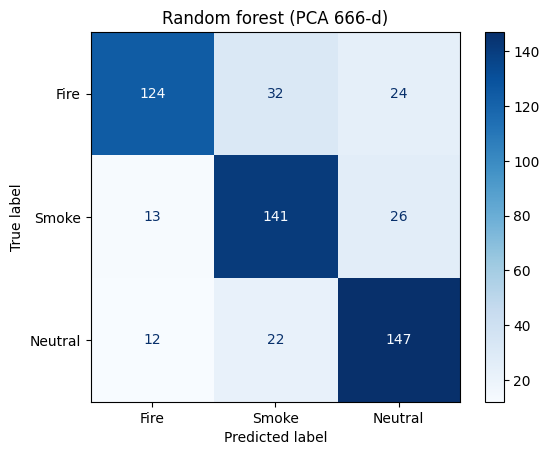

In [4]:
results = []

logreg = Pipeline([
    ("clf", LogisticRegression(max_iter=2000, multi_class="auto", random_state=42)),
])
results.append(evaluate("Logistic regression (combined 8206-d)", logreg, X_train, y_train, X_val, y_val))

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)
results.append(evaluate("Random forest (combined 8206-d)", rf, X_train, y_train, X_val, y_val))

# Same models on PCA-95% features (fit PCA on train only)
pca95 = PCA(n_components=0.95, random_state=42)
Xtr_p = pca95.fit_transform(X_train)
Xva_p = pca95.transform(X_val)
print("PCA 95% components:", Xtr_p.shape[1])

logreg_pca = LogisticRegression(max_iter=2000, random_state=42)
results.append(evaluate(f"Logistic regression (PCA {Xtr_p.shape[1]}-d)", logreg_pca, Xtr_p, y_train, Xva_p, y_val))

rf_pca = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42
)
results.append(evaluate(f"Random forest (PCA {Xtr_p.shape[1]}-d)", rf_pca, Xtr_p, y_train, Xva_p, y_val))


## Comparison


In [5]:
rows = [{k: v for k, v in r.items() if k not in ("pred", "fitted")} for r in results]
comparison_df = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

import joblib
joblib.dump(
    {r["Model"]: r["fitted"] for r in results},
    MODEL_DIR / "logreg_rf_bundle.joblib",
)
print("Saved models to", MODEL_DIR)
print("SVM remains the team baseline in 04_classifier_svm.ipynb. This notebook is the non-SVM comparison.")


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic regression (combined 8206-d),0.8207,0.8212,0.8206,0.8207
1,Logistic regression (PCA 666-d),0.8152,0.8169,0.8151,0.8154
2,Random forest (combined 8206-d),0.7782,0.7807,0.7782,0.7785
3,Random forest (PCA 666-d),0.7616,0.7672,0.7615,0.7612


Saved models to /content/MIDS-281-project/models/other_classifiers
SVM remains the team baseline in 04_classifier_svm.ipynb. This notebook is the non-SVM comparison.
